# Day 1 — Model Evaluation Basics
**System 7 · Week 3 · Commit: `day-15-model-evaluation`**

**Module A:** train-test split, cross-validation, classification and regression metrics, confusion matrix, ROC-AUC.

**Practice questions solved today:** Q1 – Q5 · **Learning topic:** Choosing the right metric

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, json
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report, roc_curve, roc_auc_score,
                             mean_absolute_error, mean_squared_error, r2_score)
plt.rcParams["figure.dpi"] = 100
RANDOM_STATE = 42
R = {}   # results collected for the README

## Dataset
Scikit-learn's **Breast Cancer Wisconsin** dataset: 569 tumours, 30 numeric features, target `0 = malignant`, `1 = benign`.

In [2]:
data = load_breast_cancer(as_frame=True)
X, y = data.data, data.target
print("Features:", X.shape, "| classes:", dict(zip(data.target_names, np.bincount(y))))
X.head(3)

Features: (569, 30) | classes: {np.str_('malignant'): np.int64(212), np.str_('benign'): np.int64(357)}


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.8,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.6,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.9,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.8,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.0,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.5,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758


## Q1 (Easy) — 80/20 split with fixed `random_state` and `stratify`
`stratify=y` keeps the class proportions the same in both parts, and `random_state` makes the split reproducible.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

print("Train shape:", X_train.shape, "| Test shape:", X_test.shape)
bal = pd.DataFrame({
    "full data": y.value_counts(normalize=True).sort_index(),
    "train": y_train.value_counts(normalize=True).sort_index(),
    "test": y_test.value_counts(normalize=True).sort_index()}).round(3)
bal.index = ["malignant (0)", "benign (1)"]
print("\nClass balance (proportion):"); print(bal)
R["q1"] = {"train": list(X_train.shape), "test": list(X_test.shape), "benign_share_train": round(float(y_train.mean()), 3), "benign_share_test": round(float(y_test.mean()), 3)}

Train shape: (455, 30) | Test shape: (114, 30)

Class balance (proportion):
               full data  train   test
malignant (0)      0.373  0.374  0.368
benign (1)         0.627  0.626  0.632


## Q2 (Easy) — Accuracy, precision, recall, F1 and confusion matrix
We scale the features and fit a logistic regression (scaling is wrapped in a pipeline so it is learned from training data only).
We treat **malignant (0)** as the *positive* class, because missing a cancer is the costly mistake.

Accuracy : 0.9825
Precision: 0.9762  (of predicted malignant, how many really are)
Recall   : 0.9762  (of real malignant, how many we caught)
F1-score : 0.9762

               precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



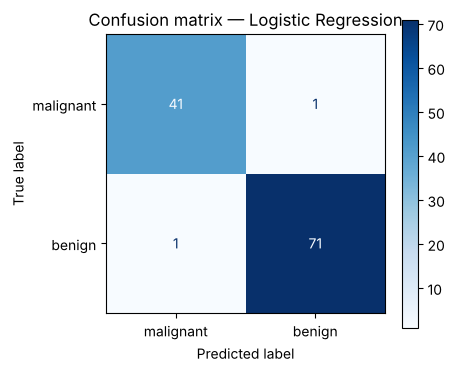

In [4]:
clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

# pos_label=0 -> malignant is the "positive" class
acc  = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, pos_label=0)
rec  = recall_score(y_test, y_pred, pos_label=0)
f1   = f1_score(y_test, y_pred, pos_label=0)
print(f"Accuracy : {acc:.4f}\nPrecision: {prec:.4f}  (of predicted malignant, how many really are)")
print(f"Recall   : {rec:.4f}  (of real malignant, how many we caught)\nF1-score : {f1:.4f}")
print("\n", classification_report(y_test, y_pred, target_names=data.target_names))

fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=data.target_names, cmap="Blues", ax=ax)
ax.set_title("Confusion matrix — Logistic Regression"); plt.show()
tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[1, 0]).ravel()   # order [benign, malignant]
R["q2"] = {"accuracy": round(acc, 4), "precision_malignant": round(prec, 4), "recall_malignant": round(rec, 4), "f1_malignant": round(f1, 4),
           "cm": confusion_matrix(y_test, y_pred).tolist()}

**Reading the matrix:** rows are the true class, columns the predicted class. The off-diagonal cells are the errors.
A *false negative* here (a malignant tumour predicted benign) is far more serious than a false positive, so **recall for malignant** is the number to watch.

## Q3 (Easy) — MAE, MSE, RMSE and R² for a house-price model (NumPy, then verified)
No house dataset ships with the syllabus, so I generate a reproducible one (1,000 houses) and save it as `houses.csv` in this folder.

In [5]:
rng = np.random.default_rng(RANDOM_STATE)
n = 1000
houses = pd.DataFrame({
    "area_sqft": rng.normal(1800, 500, n).clip(500, 4000).round(),
    "bedrooms": rng.integers(1, 6, n),
    "bathrooms": rng.integers(1, 4, n),
    "age_years": rng.integers(0, 50, n),
    "distance_to_city_km": rng.uniform(1, 30, n).round(1)})
houses["price"] = (50_000 + 120*houses.area_sqft + 8_000*houses.bedrooms + 12_000*houses.bathrooms
                   - 1_500*houses.age_years - 2_500*houses.distance_to_city_km + rng.normal(0, 20_000, n)).round(-2)
houses.to_csv("houses.csv", index=False)
houses.describe().round(1).T[["mean", "std", "min", "max"]]

,mean,std,min,max
area_sqft,1786.5,491.9,500.0,3389.0
bedrooms,3.0,1.4,1.0,5.0
bathrooms,2.0,0.8,1.0,3.0
age_years,24.3,14.8,0.0,49.0
distance_to_city_km,15.4,8.4,1.0,30.0
price,237046.1,74215.6,-10800.0,471000.0


             NumPy  scikit-learn
MAE   1.503565e+04  1.503565e+04
MSE   3.569458e+08  3.569458e+08
RMSE  1.889301e+04  1.889301e+04
R²    9.348000e-01  9.348000e-01

✅ NumPy and scikit-learn agree.


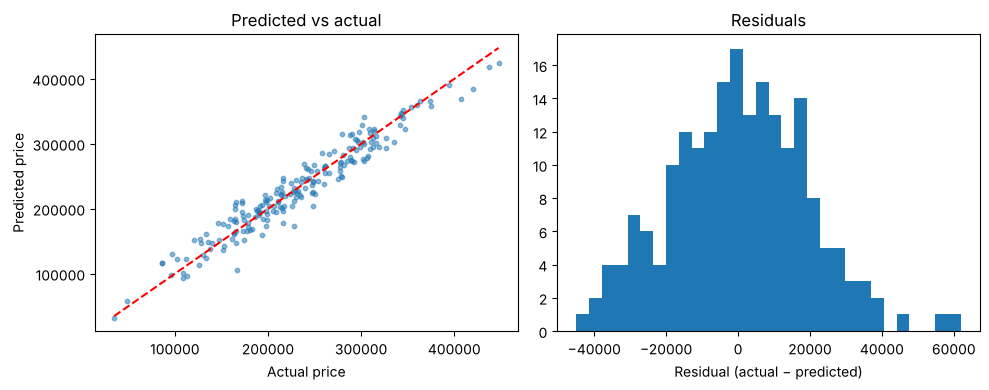

In [6]:
Xh, yh = houses.drop(columns="price"), houses["price"]
Xh_tr, Xh_te, yh_tr, yh_te = train_test_split(Xh, yh, test_size=0.2, random_state=RANDOM_STATE)
lin = LinearRegression().fit(Xh_tr, yh_tr)
y_hat = lin.predict(Xh_te)
y_true = yh_te.to_numpy()

# --- from scratch with NumPy ---
err  = y_true - y_hat
mae  = np.mean(np.abs(err))
mse  = np.mean(err ** 2)
rmse = np.sqrt(mse)
r2   = 1 - np.sum(err ** 2) / np.sum((y_true - y_true.mean()) ** 2)

# --- verify with scikit-learn ---
sk = dict(mae=mean_absolute_error(y_true, y_hat), mse=mean_squared_error(y_true, y_hat),
          rmse=np.sqrt(mean_squared_error(y_true, y_hat)), r2=r2_score(y_true, y_hat))
comp = pd.DataFrame({"NumPy": [mae, mse, rmse, r2], "scikit-learn": list(sk.values())}, index=["MAE", "MSE", "RMSE", "R²"])
print(comp.round(4))
assert np.allclose(comp["NumPy"], comp["scikit-learn"]), "mismatch!"
print("\n✅ NumPy and scikit-learn agree.")
R["q3"] = {"mae": round(mae, 1), "rmse": round(rmse, 1), "r2": round(r2, 4)}

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].scatter(y_true, y_hat, s=10, alpha=.5); ax[0].plot([y_true.min(), y_true.max()], [y_true.min(), y_true.max()], "r--")
ax[0].set(xlabel="Actual price", ylabel="Predicted price", title="Predicted vs actual")
ax[1].hist(err, bins=30); ax[1].set(xlabel="Residual (actual − predicted)", title="Residuals"); plt.tight_layout(); plt.show()

- **MAE** — average absolute error, in the same units as price (easy to explain).
- **MSE / RMSE** — squares errors first, so big mistakes are punished more; RMSE brings it back to price units.
- **R²** — share of the variance in price that the model explains (1 = perfect, 0 = no better than predicting the mean).

## Q4 (Medium) — 5-fold cross-validation on three models
A single split can be lucky or unlucky. Cross-validation trains and tests 5 times on different folds, so we get a **mean** (typical performance) and a **standard deviation** (how stable it is).

Logistic Regression  mean = 0.9737  std = 0.0166   folds = [0.974 0.947 0.965 0.991 0.991]
KNN (k=5)            mean = 0.9631  std = 0.0179   folds = [0.982 0.947 0.939 0.982 0.965]


Random Forest        mean = 0.9543  std = 0.0102   folds = [0.965 0.939 0.956 0.947 0.965]


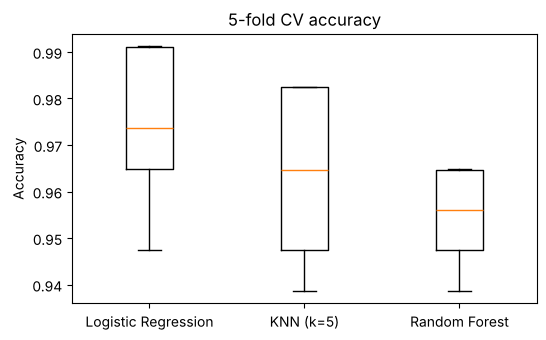

In [7]:
models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "KNN (k=5)":           make_pipeline(StandardScaler(), KNeighborsClassifier(5)),
    "Random Forest":       RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE)}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_scores = {}
for name, m in models.items():
    s = cross_val_score(m, X, y, cv=cv, scoring="accuracy")
    cv_scores[name] = s
    print(f"{name:20s} mean = {s.mean():.4f}  std = {s.std():.4f}   folds = {np.round(s, 3)}")
R["q4"] = {k: [round(v.mean(), 4), round(v.std(), 4)] for k, v in cv_scores.items()}

plt.figure(figsize=(6, 3.5)); plt.boxplot(list(cv_scores.values())); plt.xticks(range(1, 4), cv_scores.keys()); plt.ylabel("Accuracy"); plt.title("5-fold CV accuracy"); plt.show()

## Q5 (Medium) — ROC curves and AUC (Logistic Regression vs Random Forest)
The ROC curve plots **true-positive rate vs false-positive rate** as the decision threshold moves from 0 to 1. **AUC** is the area under it: 0.5 = guessing, 1.0 = perfect ranking.

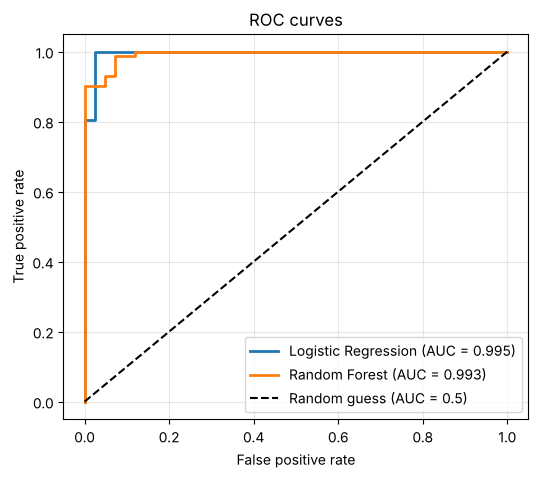

{'Logistic Regression': 0.9954, 'Random Forest': 0.9931}


In [8]:
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_train, y_train)
rf = RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE).fit(X_train, y_train)

plt.figure(figsize=(6, 5)); R["q5"] = {}
for name, m in [("Logistic Regression", lr), ("Random Forest", rf)]:
    p = m.predict_proba(X_test)[:, 1]                      # probability of benign (class 1)
    fpr, tpr, _ = roc_curve(y_test, p); auc = roc_auc_score(y_test, p)
    plt.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {auc:.3f})"); R["q5"][name] = round(auc, 4)
plt.plot([0, 1], [0, 1], "k--", label="Random guess (AUC = 0.5)")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate"); plt.title("ROC curves"); plt.legend(loc="lower right"); plt.grid(alpha=.3); plt.show()
print(R["q5"])

## Learning topic — Choosing the right metric
**Recall vs precision.** *Precision* asks "when I raise an alarm, how often am I right?"; *recall* asks "of all the real positives, how many did I catch?".
Recall matters more when a miss is expensive (cancer screening, fraud, fault detection). Precision matters more when a false alarm is expensive (spam filter deleting real mail, flagging innocent customers). **F1** is the harmonic mean of the two when you need one number.

**Why accuracy misleads on imbalanced data.** Below, a model that *always predicts "no fraud"* looks excellent on accuracy but catches nothing.

In [9]:
from sklearn.dummy import DummyClassifier
from sklearn.datasets import make_classification
Xi, yi = make_classification(n_samples=5000, weights=[0.97, 0.03], n_features=10, random_state=RANDOM_STATE)   # 3% "fraud"
Xi_tr, Xi_te, yi_tr, yi_te = train_test_split(Xi, yi, test_size=.2, stratify=yi, random_state=RANDOM_STATE)
dummy = DummyClassifier(strategy="most_frequent").fit(Xi_tr, yi_tr)
real  = LogisticRegression(max_iter=1000).fit(Xi_tr, yi_tr)

rows = []
for name, m in [("Always predict 'no fraud'", dummy), ("Logistic Regression", real)]:
    p = m.predict(Xi_te)
    rows.append([name, accuracy_score(yi_te, p), precision_score(yi_te, p, zero_division=0), recall_score(yi_te, p), f1_score(yi_te, p)])
tbl = pd.DataFrame(rows, columns=["Model", "Accuracy", "Precision", "Recall", "F1"]).round(3); print(tbl.to_string(index=False))
R["metric_demo"] = tbl.set_index("Model").to_dict("index")

                    Model  Accuracy  Precision  Recall    F1
Always predict 'no fraud'     0.964      0.000   0.000 0.000
      Logistic Regression     0.968      0.833   0.139 0.238


**Take-away:** the dummy model scores ~96% accuracy with **0% recall**. On imbalanced problems always look at recall, precision, F1 or PR/ROC-AUC, never accuracy alone.

### Summary of Day 1
| Concept | What I learned |
|---|---|
| Stratified split | Keeps class ratios equal in train and test |
| Metrics | Accuracy, precision, recall, F1 come from the confusion matrix; MAE/MSE/RMSE/R² for regression |
| Cross-validation | Gives mean ± std instead of one lucky number |
| ROC-AUC | Threshold-independent ranking quality |

In [10]:
json.dump(R, open("results.json", "w"), indent=2, default=float); print("results.json saved")

results.json saved
